# REST API

## Практические задания 
В этих практических заданиях ты будешь работать с API портала «Работа России» [https://trudvsem.ru/]

###  Задание 1. Исследование API и структуры ответа
  - Импортируй библиотеки: requests, pandas, matplotlib
  - Сформируй запрос:
      - Адрес эндпоинта вакансий
      - Параметры: page=1, per_page=2, text="python"
  - Отправь GET-запрос с таймаутом ~30 сек
  - Проверь статус: выведи status_code, убедись, что он 200
  - Распарси ответ: преобразуй JSON в структуру Python
  - Изучи структуру:
      - Выведи ключи верхнего уровня ответа
      - Найди блок results, выведи его ключи
      - Извлеки список вакансий, проверь, что он не пустой
  - Разбери первую запись:
      - Выведи ключи первого элемента списка
      - Найди внутри объект vacancy, выведи его ключи
  - Зафиксируй: выпиши названия полей, которые понадобятся для анализа   

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import requests

url = "https://opendata.trudvsem.ru/api/v1/vacancies"
params = {
    "page":1,
    "per_page":2,
    "text":"python"
}

response = requests.get(url, params=params, timeout=30 )
print(response.status_code)

data = response.json()

print("Ключи верхнего уровня:",list(data.keys()))

print(params.get("page"))
print(params.get("per_page"))
print(params.get("text"))

res = data.get("results", {})

print("Ключи results: ",list(res.keys()))

vacancies = res.get("vacancies", [])

if len(vacancies)>0:
    first_item = vacancies[0]
    print("Все ключи первого элемента списка: ",list(first_item.keys()))


vacancy = first_item.get("vacancy", {})
print("Ключи объекта vacancy: ",list(vacancy.keys()))

print(f" {"\n"}Поля, которые понадобятся для анализа:{"\n"}region, company, salary, job-name, requirements, qualification, duty, skills")


200
Ключи верхнего уровня: ['status', 'request', 'meta', 'results']
1
2
python
Ключи results:  ['vacancies']
Все ключи первого элемента списка:  ['vacancy']
Ключи объекта vacancy:  ['id', 'source', 'region', 'company', 'creation-date', 'date_modify', 'salary', 'salary_min', 'salary_max', 'job-name', 'vac_url', 'schedule', 'qualification', 'requirements', 'duty', 'category', 'requirement', 'addresses', 'social_protected', 'contact_list', 'contact_person', 'work_places', 'code_profession', 'typicalPosition', 'skills', 'workPlaceType', 'shift', 'benefit', 'trainingDays', 'currency']
 
Поля, которые понадобятся для анализа:
region, company, salary, job-name, requirements, qualification, duty, skills


###  Задание 2. Смотрим количество вакансий по запросу

  - Отправь GET-запрос с параметрами:
      - page=1, per_page=1 (достаточно для получения числа)
      - text="аналитик"
  - Распарси ответ и выведи ключи верхнего уровня
  - Найди общее число вакансий в поле meta.total
  - Выведи результат: "Найдено вакансий: X"
  - Повтори запрос для слова "python" и сравни числа


In [ ]:
import requests

url = "https://opendata.trudvsem.ru/api/v1/vacancies"
params = {
    "page":1,
    "per_page":1,
    "text":"аналитик"
}

response = requests.get(url, params=params)
data = response.json()
print(list(data.keys()))
print(f"Найдено {data.get("meta").get("total")} вакансий на должность аналитика")


['status', 'request', 'meta', 'results']
Найдено 1668 вакансий на должность аналитика


In [60]:
import requests

url = "https://opendata.trudvsem.ru/api/v1/vacancies"
params = {
    "page":1,
    "per_page":1,
    "text":"python"
}

response = requests.get(url, params=params)
data = response.json()
print(list(data.keys()))
print(f"Найдено {data.get("meta").get("total")} вакансий на должность разработчика")

['status', 'request', 'meta', 'results']
Найдено 392 вакансий на должность разработчика


###   Задание 3. Загрузка вакансий в таблицу

  - Отправь GET-запрос с параметрами:
      - page=1, per_page=10 (загружаем 10 вакансий)
      - text="аналитик"
  - Распарси ответ и извлеки список вакансий
  - Для каждой из 10 вакансий извлеки 5 ключевых полей:
      - job-name (название должности)
      - company.name (компания)
      - region.name (регион)
      - salary_min (минимальная зарплата)
      - creation-date (дата публикации)
  - Создай список словарей с этими полями: job_name, company_name, region, salary_min, published_at
  - Преобразуй список в DataFrame через pd.DataFrame()
  - Выведи:
      - Размер таблицы через .shape
      - Первые 5 строк через .head()


In [4]:
import requests
import pandas as pd

url = "https://opendata.trudvsem.ru/api/v1/vacancies"
params = {
    "page": 1,    
    "per_page": 10,    
    "text": "аналитик"
}

response = requests.get(url, params=params, timeout=30)
data = response.json()

print("Ключи верхнего уровня:", list(data.keys()))


vacancies = data.get("results", {}).get("vacancies", [])
print(f"\nНайдено вакансий: {len(vacancies)}")

parsed_vacancies = []

for item in vacancies:
    new_vacancy = {
        "job_name": item.get("vacancy", {}).get("job-name"),
        "company_name": item.get("vacancy", {}).get("company", {}).get("name"),
        "region": item.get("vacancy", {}).get("region", {}).get("name"),
        "salary_min": item.get("vacancy", {}).get("salary_min"),
        "published_at": item.get("vacancy", {}).get("creation-date")
    }
    parsed_vacancies.append(new_vacancy)


df = pd.DataFrame(parsed_vacancies)


print("\nРазмер таблицы:", df.shape)
print(df.head(5))

Ключи верхнего уровня: ['status', 'request', 'meta', 'results']

Найдено вакансий: 100

Размер таблицы: (100, 5)
              job_name                 company_name                 region  \
0             Аналитик         АО КОМБАНК "АРЗАМАС"  Нижегородская область   
1  Маркетолог-аналитик  ООО "НИЛЬСЕН ДЭЙТА ФЭКТОРИ"           Город Москва   
2             Аналитик           ООО"ДЕЛОВЫЕ ЛИНИИ"   Белгородская область   
3   Бизнес-аналитик ИТ                   ФГКУ "ЦИТ"       Тверская область   
4   Системный аналитик            АО "ГРУППА "СВЭЛ"   Свердловская область   

   salary_min published_at  
0       27500   2026-01-21  
1      120000   2026-07-13  
2       37000   2026-06-18  
3       90000   2026-09-09  
4       60000   2025-04-09  


###  Задание 4. Проверка данных и визуализация по регионам

  - Проверь структуру данных:
      - Выведи список колонок таблицы
      - Посчитай количество пропущенных значений в каждой колонке
      - Отсортируй результат по убыванию (чтобы видеть самые «проблемные» поля)
  - Подготовь данные для графика:
      - Возьми колонку с регионом (region)
      - Замени пропущенные значения на "Не указано"
      - Посчитай количество вакансий в каждом регионе
      - Оставь только топ-10 регионов по количеству
  - Построй круговую диаграмму:
      - Создай фигуру размером 8×8 дюймов
      - Построй pie-график с отображением процентов (autopct="%1.1f%%")
      - Добавь заголовок «Распределение вакансий по регионам»
      - Убери подпись оси ylabel, чтобы график выглядел аккуратнее
      - Отобрази график

Index(['job_name', 'company_name', 'region', 'salary_min', 'published_at'], dtype='object')
job_name        0
company_name    0
region          0
salary_min      0
published_at    0
dtype: int64
region
Город Москва                        23
Свердловская область                 8
Город Санкт-Петербург                7
Краснодарский край                   5
Воронежская область                  4
Московская область                   4
Республика Татарстан (Татарстан)     4
Волгоградская область                3
Белгородская область                 3
Приморский край                      3
Name: count, dtype: int64


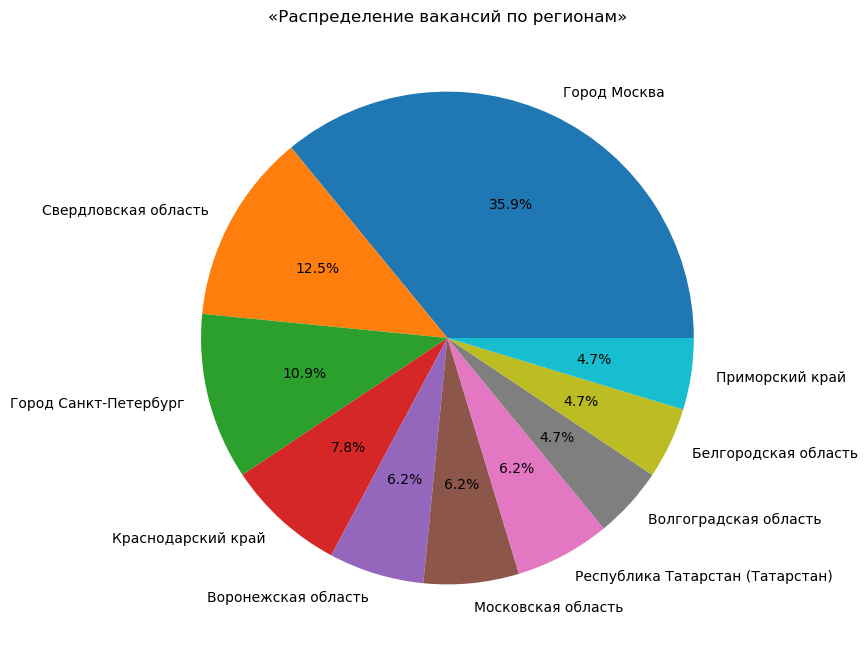

In [3]:
import requests
import pandas as pd
import matplotlib.pyplot as plt

url = "https://opendata.trudvsem.ru/api/v1/vacancies"
params = {
    "page": 1,    
    "per_page": 10,    
    "text": "аналитик"
}

response = requests.get(url, params=params, timeout=30)
data = response.json()
vacancies = data.get("results", {}).get("vacancies", [])

parsed_vacancies = []

for item in vacancies:
    new_vacancy = {
        "job_name": item.get("vacancy", {}).get("job-name"),
        "company_name": item.get("vacancy", {}).get("company", {}).get("name"),
        "region": item.get("vacancy", {}).get("region", {}).get("name"),
        "salary_min": item.get("vacancy", {}).get("salary_min"),
        "published_at": item.get("vacancy", {}).get("creation-date")
    }
    parsed_vacancies.append(new_vacancy)


df = pd.DataFrame(parsed_vacancies)

null_data = df.isnull().sum()
print(df.columns)
print(null_data.sort_values(ascending=False))
df['region']= df['region'].fillna('Не указано')

count_vacanc=df["region"].value_counts()
print(count_vacanc.head(10))


plt.figure(figsize=(8,8))
plt.pie(count_vacanc.head(10),labels = count_vacanc.head(10).index, autopct="%1.1f%%")
plt.title("«Распределение вакансий по регионам»")
plt.ylabel(' ')
plt.show()


💡 Нажмите [сюда](https://oprosso.ru/p/ad1f1715b26f48949e6103d66131cf89), чтобы отправить обратную связь по проекту. Это анонимно и поможет команде Продукта сделать твое обучение лучше.